# Beef prices and deforestation

> **To write (Andrew):** goal of the notebook. Points to cover: cattle is the first driver of tropical
> deforestation (DeDuCE), but beef is not in our crop price index; Berman et al. (2023) only add meat to their
> index in an appendix (1.27 becomes 1.54, the two indices have a within correlation of 0.98), they never
> estimate a beef effect on its own; here we test the beef price directly, at the 9 km cell level (beef price x
> cattle density in 2000) and at the country level (cattle-driven deforestation from DeDuCE, export share,
> local producer prices).

## 1. Setup

In [1]:
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
import country_converter as coco
from urllib.parse import quote

plt.style.use("default")
plt.rcParams["figure.facecolor"] = "white"
# pyfixest warns about the year x suitability controls it drops or cannot give a SE for (they are only
# controls); country_converter lists FAOSTAT regions and former countries that have no ISO3 code.
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("country_converter").setLevel(logging.ERROR)

# Data is read from GitHub. Switch BRANCH to "main" once the branch is merged.
BRANCH = "andrew-cleanup-berman"
BASE = f"https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/{BRANCH}/data/"

# The 9 km models use about 11 million cell-years (about 4 minutes and 10 GB of RAM). By default they are not
# rerun: their results are read from data/processed/results/ on GitHub. Set RECOMPUTE = True to rerun them
# locally (run the notebook from the notebooks folder); the result file is then rewritten and must be committed.
# The country-level models are always estimated here.
RECOMPUTE = False
RESULTS = "processed/results/"

# Same crops and price series as notebooks 3 and 4 (main index, 13 crops)
CROPS = {
    "banana": ["Banana, US"], "cocoa": ["Cocoa"], "coconut": ["Coconut oil"],
    "coffee": ["Coffee, Arabica", "Coffee, Robusta"], "cotton": ["Cotton, A Index"], "maize": ["Maize"],
    "oil palm": ["Palm oil"], "rice": ["Rice, Thai 5%"], "soybean": ["Soybeans"], "sugarcane": ["Sugar, world"],
    "tea": ["Tea, avg 3 auctions"], "tobacco": ["Tobacco, US import u.v."], "wheat": ["Wheat, US HRW"],
}
CROPS_13 = list(CROPS)
YEARS = list(range(2001, 2026))
REGIONS = {"Latin America & Caribbean": "LA", "Africa": "AF", "Asia-Pacific": "AP"}

SOURCE_PRICE = "Source: World Bank Commodity Price Data (Pink Sheet), real 2010 USD."
SOURCE_GRID = ("Source: Hansen et al. GFC v1.13, FAO/IIASA GAEZ v4, AGLW cattle density 2000 (Du et al. 2025), "
               "World Bank Pink Sheet; own estimates.")
SOURCE_COUNTRY = ("Source: DeDuCE (Singh and Persson 2026), FAOSTAT trade, production and producer prices, "
                  "World Bank Pink Sheet; own estimates.")


def save_or_load(name, table=None):
    """With RECOMPUTE, save the table just computed; in both cases return the saved version."""
    if RECOMPUTE:
        table.to_csv(f"../data/{RESULTS}{name}.csv", index=False)
        return pd.read_csv(f"../data/{RESULTS}{name}.csv")
    return pd.read_csv(BASE + RESULTS + name + ".csv")

## 2. Data

- **Beef price**: World Bank Pink Sheet, "Beef", real 2010 USD, base 100 in 2000 (same source as the crops).
- **Cattle density in 2000** (heads per km2): AGLW annual livestock maps (Du et al. 2025), averaged on our
  5 arc-minute cells by `scripts/build_beef_data.py`. The year 2000 is before our period, so the map is not
  shaped by the deforestation we study.
- **Cattle-driven deforestation** by country and year: DeDuCE, commodity "Cattle meat" (2001-2023).
- **Export share**: FAOSTAT exports / production of beef and buffalo meat (item 1806), built by the same script.

In [2]:
cells = pd.read_csv(BASE + "processed/grid_cells.csv.gz")
suit = pd.read_csv(BASE + "processed/grid_suitability.csv.gz").iloc[:, :14]
suit.columns = ["cell_id"] + CROPS_13
cattle = pd.read_csv(BASE + "processed/grid_cattle.csv.gz")
countries = pd.read_csv(BASE + "processed/shock_panel.csv").drop_duplicates("iso3")[["iso3", "country", "region"]]
cells = (cells.merge(suit, on="cell_id", how="left").merge(cattle, on="cell_id", how="left")
         .merge(countries[["iso3", "region"]], on="iso3", how="left"))
cells["block"] = (cells.row // 6) * 720 + cells.col // 6
cells["cattle_x"] = np.log1p(cells.cattle2000)          # exposure: log(1 + heads per km2)

prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")
P = pd.DataFrame({c: prices[prices.commodity.isin(s)].groupby("year").price_real.mean()
                  for c, s in {**CROPS, "beef": ["Beef"]}.items()})
P = 100 * P / P.loc[2000]                               # base 100 in 2000, as Berman et al.
lnB = np.log(P.beef)

print(f"{len(cells):,} cells with forest in 2000; cattle density missing for {cells.cattle2000.isna().mean():.1%}")
print("Median cattle density (heads per km2) by region:",
      cells.groupby("region").cattle2000.median().round(1).to_dict())
print(f"Real beef price, 2000 = 100: 2001 {P.beef[2001]:.0f}, 2014 {P.beef[2014]:.0f}, 2025 {P.beef[2025]:.0f}")

511,427 cells with forest in 2000; cattle density missing for 7.2%
Median cattle density (heads per km2) by region: {'Africa': 3.1, 'Asia-Pacific': 6.4, 'Latin America & Caribbean': 12.3}
Real beef price, 2000 = 100: 2001 114, 2014 193, 2025 244


One world price series for beef. Over 2001-2025 it mostly rises: a model with beef price x cattle density can
confuse the price with any trend specific to cattle areas. The crop index does not have this problem in the same
way: 13 prices move at different times.

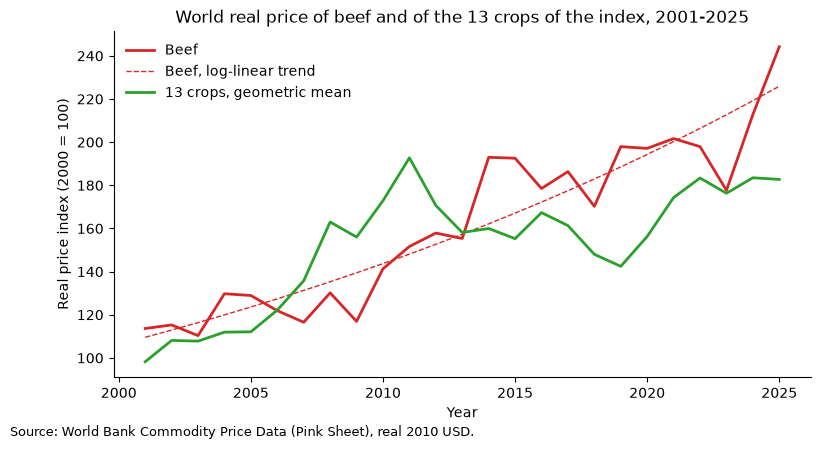

In [3]:
t = np.arange(len(YEARS))
trend = np.exp(np.polyval(np.polyfit(t, lnB.loc[YEARS], 1), t))
crop_mean = np.exp(np.log(P.loc[YEARS, CROPS_13]).mean(axis=1))      # geometric mean of the 13 crop prices

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(YEARS, P.loc[YEARS, "beef"], color="tab:red", lw=2, label="Beef")
ax.plot(YEARS, trend, color="tab:red", ls="--", lw=1, label="Beef, log-linear trend")
ax.plot(YEARS, crop_mean, color="tab:green", lw=2, label="13 crops, geometric mean")
ax.set_title("World real price of beef and of the 13 crops of the index, 2001-2025")
ax.set_xlabel("Year")
ax.set_ylabel("Real price index (2000 = 100)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, SOURCE_PRICE, fontsize=9)
fig.savefig("../figures/beef_price.png", dpi=200, bbox_inches="tight")
plt.show()

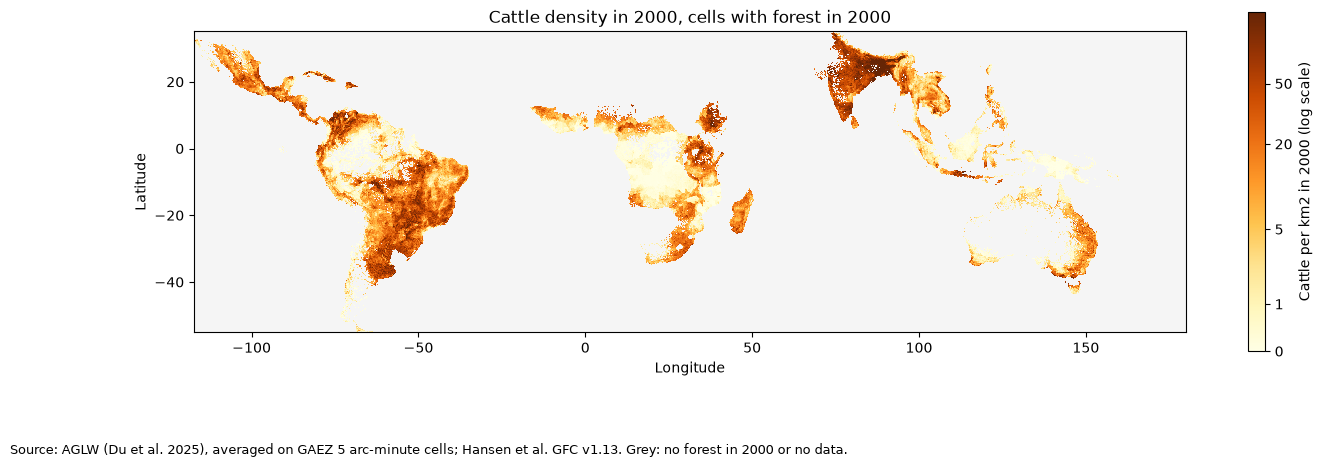

In [4]:
def to_grid(values):
    """Put one value per cell back on the 2160 x 4320 GAEZ grid, cropped to the sample."""
    g = np.full((2160, 4320), np.nan)
    g[cells.row.values, cells.col.values] = values
    r0, r1 = cells.row.min(), cells.row.max() + 1
    c0, c1 = cells.col.min(), cells.col.max() + 1
    extent = [-180 + c0 / 12, -180 + c1 / 12, 90 - r1 / 12, 90 - r0 / 12]
    return g[r0:r1, c0:c1], extent

g, extent = to_grid(cells.cattle_x.values)
fig, ax = plt.subplots(figsize=(16, 5.5))
ax.set_facecolor("whitesmoke")
im = ax.imshow(g, extent=extent, cmap="YlOrBr", vmin=0, vmax=np.nanpercentile(g, 99), interpolation="nearest")
ticks = [0, 1, 5, 20, 50, 150]
cb = fig.colorbar(im, ax=ax, shrink=0.8, ticks=np.log1p(ticks))
cb.ax.set_yticklabels(ticks)
cb.set_label("Cattle per km2 in 2000 (log scale)")
ax.set_title("Cattle density in 2000, cells with forest in 2000")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.text(0.01, 0.0, "Source: AGLW (Du et al. 2025), averaged on GAEZ 5 arc-minute cells; Hansen et al. GFC v1.13. "
         "Grey: no forest in 2000 or no data.", fontsize=9)
fig.savefig("../figures/cattle_density_2000.png", dpi=200, bbox_inches="tight")
plt.show()

Is the cattle map different from the crop suitability maps? If it were the same map, a beef term could not be
separated from the crop index. We compare them within countries (what remains after country fixed effects).

In [5]:
X = cells[CROPS_13 + ["cattle_x", "iso3"]].dropna()
within = X.drop(columns="iso3").groupby(X.iso3.values).transform(lambda s: s - s.mean())
within["all 13 crops"] = within[CROPS_13].sum(axis=1)
within.corr()["cattle_x"].drop("cattle_x").sort_values(ascending=False).round(2).to_frame(
    "within-country correlation with log cattle density")

,within-country correlation with log cattle density
wheat,0.37
tobacco,0.36
soybean,0.30
cotton,0.29
maize,0.27
all 13 crops,0.19
tea,0.15
rice,0.14
sugarcane,0.10
coffee,0.02


## 3. Cell level: beef price x cattle density in 2000

Same equation as the main model of notebook 4 (9 km cells, 2001-2025, cell and country x year fixed effects,
standard errors clustered by 0.5 degree block, also by country), with one more term:

`asinh(Defor[c,t]) = beta ln Price[c,t] + gamma ln P_beef[t] x ln(1 + Cattle2000[c]) + avg suitability[c] x year + eta[c] + nu[country,t]`

The control average suitability x year is the robustness of Berman et al. (Figure OA.12). We then add the
checks that matter for one trending price: a linear trend of cattle cells (cattle x trend), forest cover in
2000 x year (forest depletion), the beef price without its trend, moving averages (persistent prices) and
5-year periods (long differences).

In [6]:
if RECOMPUTE:
    S = cells[CROPS_13].to_numpy(float)
    tot = S.sum(axis=1, keepdims=True)
    alpha = np.divide(S, tot, out=np.full_like(S, np.nan), where=tot > 0)
    lnP = np.log(alpha @ P.loc[YEARS, CROPS_13].to_numpy().T)           # cells x years
    T = len(YEARS)
    rep = lambda col: np.repeat(cells[col].to_numpy(), T)
    d = pd.DataFrame({
        "cell_id": rep("cell_id"), "year": np.tile(YEARS, len(cells)),
        "loss": cells[[f"loss25_{y}" for y in YEARS]].to_numpy().ravel(),
        "lnP": lnP.ravel().astype(np.float32),
        "avg_suit": np.repeat(cells[CROPS_13].mean(axis=1).to_numpy(), T).astype(np.float32),
        "lforest": np.repeat(np.log1p(cells.forest25_px.to_numpy()), T).astype(np.float32),
        "cx": rep("cattle_x").astype(np.float32), "block": rep("block"), "region": rep("region"),
        "country": np.repeat(pd.Categorical(cells.iso3).codes.astype(np.int32), T),
    })
    d["y"] = np.arcsinh(d.loss).astype(np.float32)
    d["ct"] = d.country * 10000 + d.year
    d["tr"] = ((d.year - 2013) / 10).astype(np.float32)
    d["cx_tr"] = d.cx * d.tr
    res_b = lnB.loc[YEARS] - np.polyval(np.polyfit(np.arange(T), lnB.loc[YEARS], 1), np.arange(T))
    for name, s in {"beef": lnB, "beef_ma3": np.log(P.beef.rolling(3).mean()),
                    "beef_ma5": np.log(P.beef.rolling(5).mean()), "beef_detr": res_b}.items():
        d[name] = (d.cx * d.year.map(s)).astype(np.float32)
    for reg, code in REGIONS.items():
        d[f"beef_{code}"] = (d.beef * (d.region == reg)).astype(np.float32)
        d[f"cx_tr_{code}"] = (d.cx_tr * (d.region == reg)).astype(np.float32)
    d = d.dropna(subset=["lnP", "cx"]).reset_index(drop=True)

    rows = []
    def run(label, fml, data, keep):
        fit = pf.feols(fml, data, vcov={"CRV1": "block"}, copy_data=False)
        tb = fit.tidy()
        se_c = fit.vcov({"CRV1": "country"}).tidy()["Std. Error"]
        for v in keep:
            rows.append({"model": label, "term": v, "Estimate": tb.loc[v, "Estimate"],
                         "SE block": tb.loc[v, "Std. Error"], "SE country": se_c[v], "N": fit._N})

    C = "+ i(year, avg_suit) | cell_id + ct"
    run("1 Annual beef price", f"y ~ lnP + beef {C}", d, ["lnP", "beef"])
    run("2 3-year moving average", f"y ~ lnP + beef_ma3 {C}", d.dropna(subset=["beef_ma3"]), ["lnP", "beef_ma3"])
    run("3 5-year moving average", f"y ~ lnP + beef_ma5 {C}", d.dropna(subset=["beef_ma5"]), ["lnP", "beef_ma5"])
    run("4 + forest 2000 x year", f"y ~ lnP + beef + i(year, lforest) {C}", d, ["lnP", "beef"])
    run("5 + cattle x trend", f"y ~ lnP + beef + cx_tr {C}", d, ["lnP", "beef"])
    run("6 + cattle x trend + forest 2000 x year", f"y ~ lnP + beef + cx_tr + i(year, lforest) {C}", d,
        ["lnP", "beef"])
    run("7 Beef price without its trend", f"y ~ lnP + beef_detr {C}", d, ["lnP", "beef_detr"])
    run("8 By region", f"y ~ lnP + beef_LA + beef_AF + beef_AP {C}", d, ["beef_LA", "beef_AF", "beef_AP"])
    run("9 By region + cattle x trend by region",
        f"y ~ lnP + beef_LA + beef_AF + beef_AP + cx_tr_LA + cx_tr_AF + cx_tr_AP {C}", d,
        ["beef_LA", "beef_AF", "beef_AP"])

    # Long differences: five 5-year periods, outcome = asinh of pixels lost in the period, regressors = means
    d["period"] = (d.year - 2001) // 5
    g5 = d.groupby(["cell_id", "period"]).agg(loss=("loss", "sum"), lnP=("lnP", "mean"), beef=("beef", "mean"),
                                              avg_suit=("avg_suit", "first"), block=("block", "first"),
                                              country=("country", "first")).reset_index()
    g5["y"], g5["cp"] = np.arcsinh(g5.loss), g5.country * 100 + g5.period
    run("10 5-year periods (long differences)", "y ~ lnP + beef + i(period, avg_suit) | cell_id + cp", g5,
        ["lnP", "beef"])
    t = pd.DataFrame(rows)
    del d, g5
grid = save_or_load("beef_grid_9km", t if RECOMPUTE else None)
grid.round(3)

,model,term,Estimate,SE block,SE country,N
0,1 Annual beef price,lnP,1.082,0.035,0.200,11354300
1,1 Annual beef price,beef,-0.256,0.013,0.063,11354300
2,2 3-year moving average,lnP,1.089,0.035,0.203,11354300
3,2 3-year moving average,beef_ma3,-0.273,0.014,0.072,11354300
4,3 5-year moving average,lnP,1.089,0.035,0.195,11354300
5,3 5-year moving average,beef_ma5,-0.257,0.014,0.064,11354300
6,4 + forest 2000 x year,lnP,0.943,0.036,0.163,11354300
7,4 + forest 2000 x year,beef,-0.211,0.013,0.058,11354300
8,5 + cattle x trend,lnP,1.078,0.035,0.197,11354300
9,5 + cattle x trend,beef,-0.032,0.014,0.114,11354300


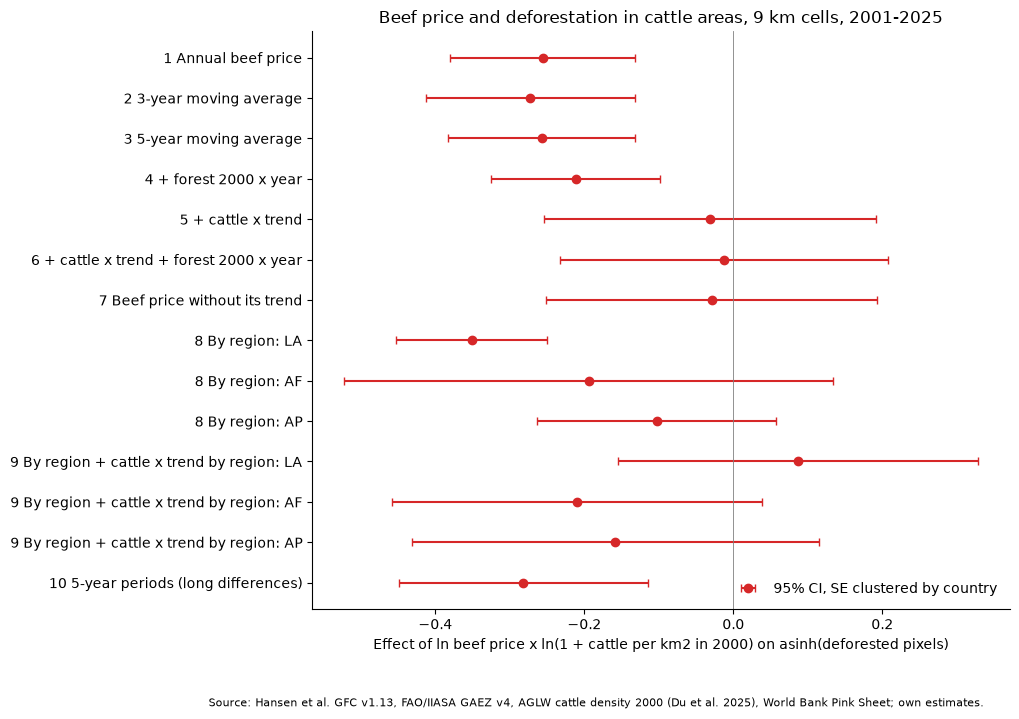

In [7]:
b = grid[grid.term.str.startswith("beef")].reset_index(drop=True)
labels = b.model + np.where(b.term.str[-2:].isin(list(REGIONS.values())), ": " + b.term.str[-2:], "")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(b) + 1.2))
y = np.arange(len(b))[::-1]
ax.errorbar(b.Estimate, y, xerr=1.96 * b["SE country"], fmt="o", capsize=3, color="tab:red",
            label="95% CI, SE clustered by country")
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("Effect of ln beef price x ln(1 + cattle per km2 in 2000) on asinh(deforested pixels)")
ax.set_title("Beef price and deforestation in cattle areas, 9 km cells, 2001-2025")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, SOURCE_GRID, fontsize=8)
fig.savefig("../figures/beef_grid_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

> **To write (Andrew):** what the cell-level results show. Points to cover: without trend controls the beef term
> is negative and very stable (about -0.26 whatever the price: annual, moving averages, 5-year periods), strongest
> in Latin America (-0.35); it is not forest depletion (forest 2000 x year moves it only to about -0.21); once cattle
> cells get their own linear trend, the beef effect is about zero (-0.03, 95% CI about -0.25 to +0.19), and the
> beef price without its trend gives the same; by region with their own trends, nothing is significant
> (Latin America +0.09, se 0.12). Interpretation: deforestation moved away from old cattle areas
> towards new frontiers while the beef price doubled; with one price series the persistent part of the price
> cannot be separated from trends, and the temporary part has no effect (consistent with the literature: Assuncao,
> Gandour and Rocha 2015 find a mixed effect of cattle prices). The crop index stays between 0.94 and 1.23.

## 4. Country level: cattle-driven deforestation and the export share

If world beef prices only reach farmers in exporting countries, cattle-driven deforestation (DeDuCE) should react
to the world beef price more where a large share of beef is exported:

`asinh(CattleDefor[i,t]) = b ln P_beef[t] x ExportShare[i] + country FE + year FE`, SE clustered by country.

Placebo: the same model for deforestation attributed to crops should give nothing.

In [8]:
DEDUCE = "1. DeDuCE_Deforestation_attributed to agricultural and forestry commodities (2001-2023).xlsx"
x = pd.read_excel(BASE + "raw/crops/" + quote(DEDUCE), sheet_name="Deforestation attribution")
x = x[x.ISO.isin(countries.iso3)]
x["kind"] = np.select([x.Commodity == "Cattle meat", ~x["Commodity group"].isin(["Pasture", "Forest plantation"])],
                      ["cattle", "crops"], "other")
DEDUCE_YEARS = range(2001, 2024)
cd = (x.pivot_table(index=["ISO", "Year"], columns="kind", values="Deforestation attribution, unamortized (ha)",
                    aggfunc="sum")
      .reindex(pd.MultiIndex.from_product([countries.iso3, DEDUCE_YEARS], names=["iso3", "year"]))
      .fillna(0).reset_index())
share = pd.read_csv(BASE + "processed/beef_export_share.csv")
cd = cd.merge(share[["iso3", "country", "share_9600", "share_0123"]], on="iso3")
cd["y_cattle"], cd["y_crops"] = np.arcsinh(cd.cattle), np.arcsinh(cd.crops)
cd["lpb"] = cd.year.map(lnB)
for s in ("share_9600", "share_0123"):
    cd[f"x_{s}"] = cd.lpb * cd[s]
cd["x_exporter"] = cd.lpb * (cd.share_0123 > 0.1)
cd["t"] = cd.year - 2012

tot = cd.groupby("country").cattle.sum().sort_values(ascending=False) / 1e6
print(f"Cattle-driven deforestation 2001-2023 in the 62 countries: {tot.sum():.1f} Mha, "
      f"Brazil {tot.iloc[0]:.1f} Mha ({tot.iloc[0] / tot.sum():.0%})")
share.sort_values("share_0123", ascending=False).head(10)[["country", "share_9600", "share_0123"]].round(2)

Cattle-driven deforestation 2001-2023 in the 62 countries: 46.9 Mha, Brazil 31.9 Mha (68%)


,country,share_9600,share_0123
42,Nicaragua,0.54,0.92
24,Equatorial Guinea,0.00,0.88
48,Paraguay,0.15,0.69
2,Australia,0.59,0.62
14,Costa Rica,0.22,0.29
58,Vanuatu,0.54,0.28
29,India,0.06,0.26
6,Brazil,0.02,0.20
52,Thailand,0.00,0.16
40,Malaysia,0.10,0.16


In [9]:
def country_model(label, fml, data):
    fit = pf.feols(fml, data, vcov={"CRV1": "iso3"})
    v = [i for i in fit.coef().index if i.startswith("x_")][0]
    tb = fit.tidy().loc[v]
    return {"model": label, "Estimate": tb["Estimate"], "SE country": tb["Std. Error"], "p": tb["Pr(>|t|)"],
            "N": fit._N}

exp_res = pd.DataFrame([
    country_model("Cattle, export share 1996-2000", "y_cattle ~ x_share_9600 | iso3 + year", cd),
    country_model("Cattle, export share 2001-2023", "y_cattle ~ x_share_0123 | iso3 + year", cd),
    country_model("Cattle, exporter (share > 10%)", "y_cattle ~ x_exporter | iso3 + year", cd),
    country_model("Cattle, share 2001-2023 + country trends", "y_cattle ~ x_share_0123 + i(iso3, t) | iso3 + year", cd),
    country_model("Cattle, share 2001-2023, without Brazil", "y_cattle ~ x_share_0123 | iso3 + year",
                  cd[cd.iso3 != "BRA"]),
    country_model("Placebo crops, export share 1996-2000", "y_crops ~ x_share_9600 | iso3 + year", cd),
    country_model("Placebo crops, export share 2001-2023", "y_crops ~ x_share_0123 | iso3 + year", cd),
])
exp_res.round(3)

,model,Estimate,SE country,p,N
0,"Cattle, export share 1996-2000",3.449,6.930,0.620,1403
1,"Cattle, export share 2001-2023",-0.210,3.277,0.949,1403
2,"Cattle, exporter (share > 10%)",-0.526,1.481,0.724,1426
3,"Cattle, share 2001-2023 + country trends",0.684,2.385,0.775,1403
4,"Cattle, share 2001-2023, without Brazil",-0.091,3.311,0.978,1380
5,"Placebo crops, export share 1996-2000",-10.098,4.884,0.043,1403
6,"Placebo crops, export share 2001-2023",-2.892,3.466,0.407,1403


## 5. Country level: local producer prices

Does cattle-driven deforestation follow the price farmers actually receive? FAOSTAT producer prices of cattle
meat (USD per tonne, `FAOSTAT_2.0.csv`, as in David's notebook). Year fixed effects absorb US dollar inflation.
Countries with at least 10 years of prices. Warning: more clearing means more beef and a lower local price
(reverse causality), so this is a correlation, not a causal effect.

In [10]:
pp = pd.read_csv(BASE + "raw/crops/FAOSTAT_2.0.csv")
pp = pp[pp.Item.str.startswith("Meat of cattle")].copy()
pp["iso3"] = coco.convert(names=[int(str(m).strip("'")) for m in pp["Area Code (M49)"]], src="UNnumeric",
                          to="ISO3", not_found=None)
pp = pp[pp.iso3.isin(countries.iso3)][["iso3", "Year", "Value"]].rename(columns={"Year": "year"})
lp = cd.merge(pp, on=["iso3", "year"], how="left").sort_values(["iso3", "year"])
lp["x_lp"] = np.log(lp.Value)
lp["x_lp_l1"] = lp.groupby("iso3").x_lp.shift(1)
n_years = lp.dropna(subset=["x_lp"]).groupby("iso3").size()
lp10 = lp[lp.iso3.isin(n_years.index[n_years >= 10])]
cover = lp10.groupby("iso3").cattle.sum().sum() / cd.cattle.sum()
print(f"{len(n_years)} sample countries have a local beef price, {(n_years >= 10).sum()} with at least 10 years; "
      f"they account for {cover:.0%} of cattle-driven deforestation. "
      f"Brazil has prices for {n_years.get('BRA', 0)} years only.")

local_res = pd.DataFrame([
    country_model("Cattle, local price t", "y_cattle ~ x_lp | iso3 + year", lp10),
    country_model("Cattle, local price t-1", "y_cattle ~ x_lp_l1 | iso3 + year", lp10),
    country_model("Cattle, local price t-1 + country trends", "y_cattle ~ x_lp_l1 + i(iso3, t) | iso3 + year", lp10),
    country_model("Placebo crops, local price t-1", "y_crops ~ x_lp_l1 | iso3 + year", lp10),
])
local_res.round(3)

30 sample countries have a local beef price, 14 with at least 10 years; they account for 6% of cattle-driven deforestation. Brazil has prices for 6 years only.


,model,Estimate,SE country,p,N
0,"Cattle, local price t",-0.784,0.886,0.392,249
1,"Cattle, local price t-1",-1.930,1.071,0.095,241
2,"Cattle, local price t-1 + country trends",-0.487,1.180,0.686,241
3,"Placebo crops, local price t-1",1.397,1.056,0.208,241


> **To write (Andrew):** what the country-level results show. Points to cover: Brazil alone is about two thirds
> of cattle-driven deforestation in the sample; export shares are high in few countries (Nicaragua, Paraguay,
> Australia...) and Brazil only became an exporter after 2000; no export-share effect in any version, with very
> large standard errors (a test without power, not a proof of no effect), and one placebo is significant, a sign
> of noise; local producer prices are missing for the countries that matter (the 14 countries with 10 years of
> prices make only 6% of cattle-driven deforestation; Brazil 2001-2006 only, nothing for Paraguay) and the negative sign fits reverse causality.

## 6. Summary for the article

In [11]:
summary = pd.concat([
    grid.assign(level="9 km cells", **{"SE": grid["SE country"]})[["level", "model", "term", "Estimate", "SE", "N"]],
    exp_res.assign(level="countries, export share", term="beef x share")[
        ["level", "model", "term", "Estimate", "SE country", "N"]].rename(columns={"SE country": "SE"}),
    local_res.assign(level="countries, local price", term="local price")[
        ["level", "model", "term", "Estimate", "SE country", "N"]].rename(columns={"SE country": "SE"}),
], ignore_index=True)
# Export for the article notebook (6-Article.ipynb). Cheap: always rewritten.
summary.to_csv(f"../data/{RESULTS}beef_summary.csv", index=False)
summary.round(3)

,level,model,term,Estimate,SE,N
0,9 km cells,1 Annual beef price,lnP,1.082,0.200,11354300
1,9 km cells,1 Annual beef price,beef,-0.256,0.063,11354300
2,9 km cells,2 3-year moving average,lnP,1.089,0.203,11354300
3,9 km cells,2 3-year moving average,beef_ma3,-0.273,0.072,11354300
4,9 km cells,3 5-year moving average,lnP,1.089,0.195,11354300
5,9 km cells,3 5-year moving average,beef_ma5,-0.257,0.064,11354300
6,9 km cells,4 + forest 2000 x year,lnP,0.943,0.163,11354300
7,9 km cells,4 + forest 2000 x year,beef,-0.211,0.058,11354300
8,9 km cells,5 + cattle x trend,lnP,1.078,0.197,11354300
9,9 km cells,5 + cattle x trend,beef,-0.032,0.114,11354300


> **To write (Andrew):** conclusion in 3 sentences for section 9 of the article. Suggested thread: with world
> data, the beef price does not explain deforestation in a reliable way: either the world price does not reach
> farmers (David, 0 of 21 countries), or its effect cannot be separated from the trends of cattle areas (one
> price series). This is why the index keeps the 13 crops; cattle stays the main limit, and a study of Brazil
> with local cattle prices and municipal data (as Assuncao et al. 2015, or slaughterhouse openings, Da Mata et
> al.) is the natural extension.